# PDS-H backend analysis

Run the setup cell once, then use the single `plot_results(...)` call in the final cell to create a graph with new parameters. Results are read from `tpch_backend_results/analysis_results` and repeated durations are averaged.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
analysis_results_dir = repo_root / "tpch_backend_results" / "analysis_results"


In [35]:
def load_analysis_results(root=analysis_results_dir):
    """Load every duration stored under q{query}/{scale}/{backend}.*."""
    if not root.exists():
        raise FileNotFoundError(f"Analysis results folder was not found at {root}")
    records = []
    for path in root.glob("q*/*/*"):
        if not path.is_file():
            continue
        query = int(path.parent.parent.name.removeprefix("q"))
        scale_factor = float(path.parent.name)
        suffix = "_exclude_conversion_time"
        exclude_conversion_time = path.name.endswith(suffix)
        backend = path.name.removesuffix(suffix)
        records.extend(
            {
                "query": query,
                "scale_factor": scale_factor,
                "backend": backend,
                "exclude_conversion_time": exclude_conversion_time,
                "mean_seconds": float(duration),
            }
            for duration in path.read_text().splitlines()
            if duration
        )
    if not records:
        raise ValueError(f"No analysis results were found under {root}")
    return pd.DataFrame(records)


def _values(data, values, column):
    if values is None:
        return sorted(data[column].unique())
    if not isinstance(values, (list, tuple, set)):
        values = [values]
    if pd.api.types.is_numeric_dtype(data[column]):
        return [float(value) for value in values]
    return list(values)

def table_results(
    queries=None,
    scale_factor=None,
    exclude_conversion_time=True,
    root=analysis_results_dir,
):
    """Create a table of average query runtimes by implementation."""
    results = load_analysis_results(root)

    queries = _values(results, queries, "query")
    scale_factors = _values(results, scale_factor, "scale_factor")
    selected = results[
        results["query"].isin(queries)
        & results["scale_factor"].isin(scale_factors)
        & (results["exclude_conversion_time"] == exclude_conversion_time)
    ]

    if selected.empty:
        raise ValueError("No analysis results match the table parameters")

    averages = selected.groupby(
        ["query", "backend"], as_index=False
    ).agg(
        mean_seconds=("mean_seconds", "mean")
    )

    display_names = {
        "triton": "triton",
        "combined_triton": "combined triton",
        "cudf": "cuDF",
    }

    table = averages.pivot(
        index="query",
        columns="backend",
        values="mean_seconds",
    )

    table = table.rename(columns=display_names)

    backend_order = ["triton", "combined triton", "cuDF"]
    table = table.reindex(
        columns=[b for b in backend_order if b in table.columns]
    )

    table.index = [f"Q{int(q)}" for q in table.index]
    table.index.name = "Query"

    return table

def plot_results(
    queries=None,
    backends=None,
    scale_factor=None,
    exclude_conversion_time=True,
    root=analysis_results_dir,
):
    """Filter, average, and plot saved benchmark durations."""
    display_names = {
        "cudf": "cuDF",
        "combined_triton": "combined triton",
    }
    backend_colors = {
        "triton": "C0",
        "combined triton": "C0",
        "cuDF": "C1",
    }

    results = load_analysis_results(root)
    queries = _values(results, queries, "query")
    scale_factors = _values(results, scale_factor, "scale_factor")
    backends = _values(results, backends, "backend")
    selected = results[
        results["query"].isin(queries)
        & results["scale_factor"].isin(scale_factors)
        & results["backend"].isin(backends)
        & (results["exclude_conversion_time"] == exclude_conversion_time)
    ]
    if selected.empty:
        raise ValueError("No analysis results match the plotting parameters")
    averages = selected.groupby(
        ["query", "scale_factor", "backend"], as_index=False
    ).agg(mean_seconds=("mean_seconds", "mean"), runs=("mean_seconds", "size"))
    averages["plot_backend"] = averages["backend"].replace(display_names)
    
    colors = [
        backend_colors[backend]
        for backend in averages["plot_backend"].unique()
    ]
    if len(scale_factors) > 1:
        data = averages.groupby(["scale_factor", "backend"], as_index=False).agg(
            mean_seconds=("mean_seconds", "mean")
        )
        data.pivot(index="scale_factor", columns="plot_backend", values="mean_seconds").plot(
            marker="o", figsize=(10, 5), color=colors,
        )
        plt.title("Average runtime over queries by scale factor")
        plt.xlabel("Scale factor")
    else:
        backend_order = ["cuDF", "triton", "combined triton"]
        averages.pivot(index="query", columns="plot_backend", values="mean_seconds").reindex(columns=[
            backend for backend in backend_order
            if backend in averages["plot_backend"].unique()
        ]).plot.bar(
            figsize=(10, 5),
            color=[
                backend_colors[backend]
                for backend in backend_order
                if backend in averages["plot_backend"].unique()
            ],
        )
        plt.title("Average query runtime")
        plt.xlabel("Query")
    plt.ylabel("Seconds; lower is better")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
    return averages


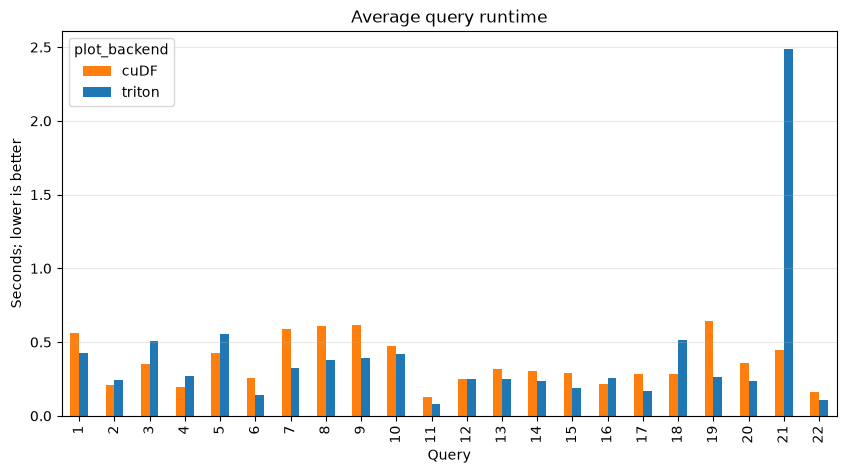

In [38]:
_ = plot_results(
    queries=None,
    backends=["triton", "cudf"],
    scale_factor="5.0",
    exclude_conversion_time=True,
)

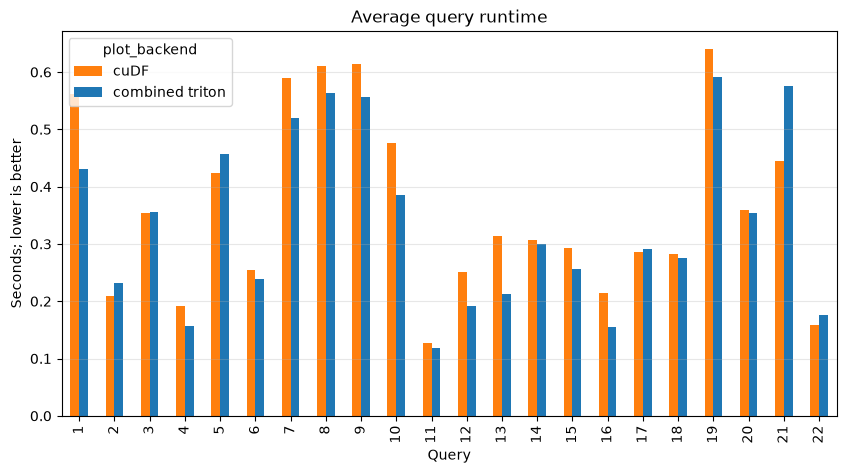

In [41]:
_ = plot_results(
    queries=None,
    backends=["combined_triton", "cudf"],
    scale_factor="5.0",
    exclude_conversion_time=True,
)


In [40]:
table = table_results(
    queries=None,
    scale_factor="5.0",
    exclude_conversion_time=True,
)

display(table)

backend,triton,combined triton,cuDF
Query,,,
Q1,0.422759,0.431127,0.561722
Q2,0.242142,0.231649,0.209865
Q3,0.504861,0.356584,0.353816
Q4,0.269105,0.156839,0.192142
Q5,0.558178,0.456954,0.424361
Q6,0.138355,0.238758,0.254184
Q7,0.322383,0.520381,0.589383
Q8,0.378041,0.562711,0.609683
Q9,0.393796,0.556509,0.614176
